# 02 — Biến thể A1: Harris–Laplace

Notebook này khảo sát khả năng chọn tỉ lệ đặc trưng. Harris cổ điển chỉ trả `(row, col, response)`, còn Harris–Laplace trả `(row, col, sigma, response)`.

## Ý tưởng

1. Xây tháp tỉ lệ `sigma_n = sigma0 * xi**n`.
2. Ở mỗi tỉ lệ, tính Harris với `sigma_i=sigma_n` và `sigma_d=0.7*sigma_n`, rồi lấy NMS và lọc ngưỡng.
3. Tính LoG chuẩn hóa `sigma² * |Lxx + Lyy|`; giữ điểm tại tỉ lệ mà LoG là cực đại địa phương theo trục scale.

**Điểm cốt lõi:** không chọn đơn giản `argmax Harris response` theo scale. Điều kiện cực đại LoG là bước chọn tỉ lệ.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import matplotlib.pyplot as plt
from cv_bt2.corner import *
from cv_bt2.data.synthetic import *
from cv_bt2.visualization import plot_corners, plot_labels

OUT = ROOT / "outputs" / "figures"
OUT.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)


Project root: /mnt/data/Computer_Vision_BT2


## 1. Hai ảnh cùng cấu trúc, khác kích thước

Ta tạo ảnh bàn cờ 120×120 rồi phóng to 3 lần. Đây là dữ liệu tổng hợp có phép biến đổi đã biết, vì vậy có thể ánh xạ tọa độ `(row,col)` từ ảnh nhỏ sang ảnh lớn bằng phép nhân 3.

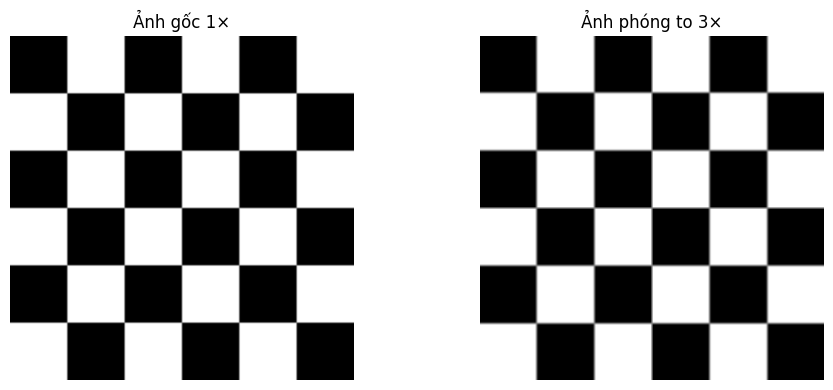

(120, 120) -> (360, 360)


In [2]:
img_small = checkerboard_image((120,120), squares=6)
img_large = scale_image(img_small, 3.0, order=1)
fig, ax = plt.subplots(1,2,figsize=(10,4))
ax[0].imshow(img_small,cmap="gray"); ax[0].set_title("Ảnh gốc 1×"); ax[0].axis("off")
ax[1].imshow(img_large,cmap="gray"); ax[1].set_title("Ảnh phóng to 3×"); ax[1].axis("off")
plt.tight_layout(); plt.show()
print(img_small.shape, "->", img_large.shape)

## 2. Chạy Harris cổ điển và Harris–Laplace

Dải tỉ lệ của ảnh lớn cần vươn tới các sigma lớn hơn vì hình học đã được phóng to. Ở đây dùng cùng `sigma0`, `xi`, nhưng nhiều tầng hơn cho ảnh 3×.

In [3]:
transform_3x = lambda r,c: (3.0*r, 3.0*c)
# Detector Harris cổ điển (một scale mặc định)
p_h_small = harris_classic(img_small)
p_h_large = harris_classic(img_large)
rep_harris = repeatability(p_h_small,p_h_large,transform_3x,img_large.shape,eps=4.0)

sigmas_small = scale_pyramid(sigma0=0.25, xi=1.2, n_levels=10)
sigmas_large = scale_pyramid(sigma0=0.25, xi=1.2, n_levels=16)
p_hl_small = harris_laplace(img_small,sigmas_small,log_thresh=0.0)
p_hl_large = harris_laplace(img_large,sigmas_large,log_thresh=0.0)
rep_hl = repeatability(p_hl_small,p_hl_large,transform_3x,img_large.shape,eps=4.0)
print(f"Harris:        {len(p_h_small)} -> {len(p_h_large)} điểm; repeatability={rep_harris:.3f}")
print(f"Harris-Laplace:{len(p_hl_small)} -> {len(p_hl_large)} điểm; repeatability={rep_hl:.3f}")
print("Harris–Laplace trả về sigma đặc trưng, Harris cổ điển không có trường scale.")

Harris:        25 -> 81 điểm; repeatability=1.000
Harris-Laplace:13 -> 81 điểm; repeatability=1.000
Harris–Laplace trả về sigma đặc trưng, Harris cổ điển không có trường scale.


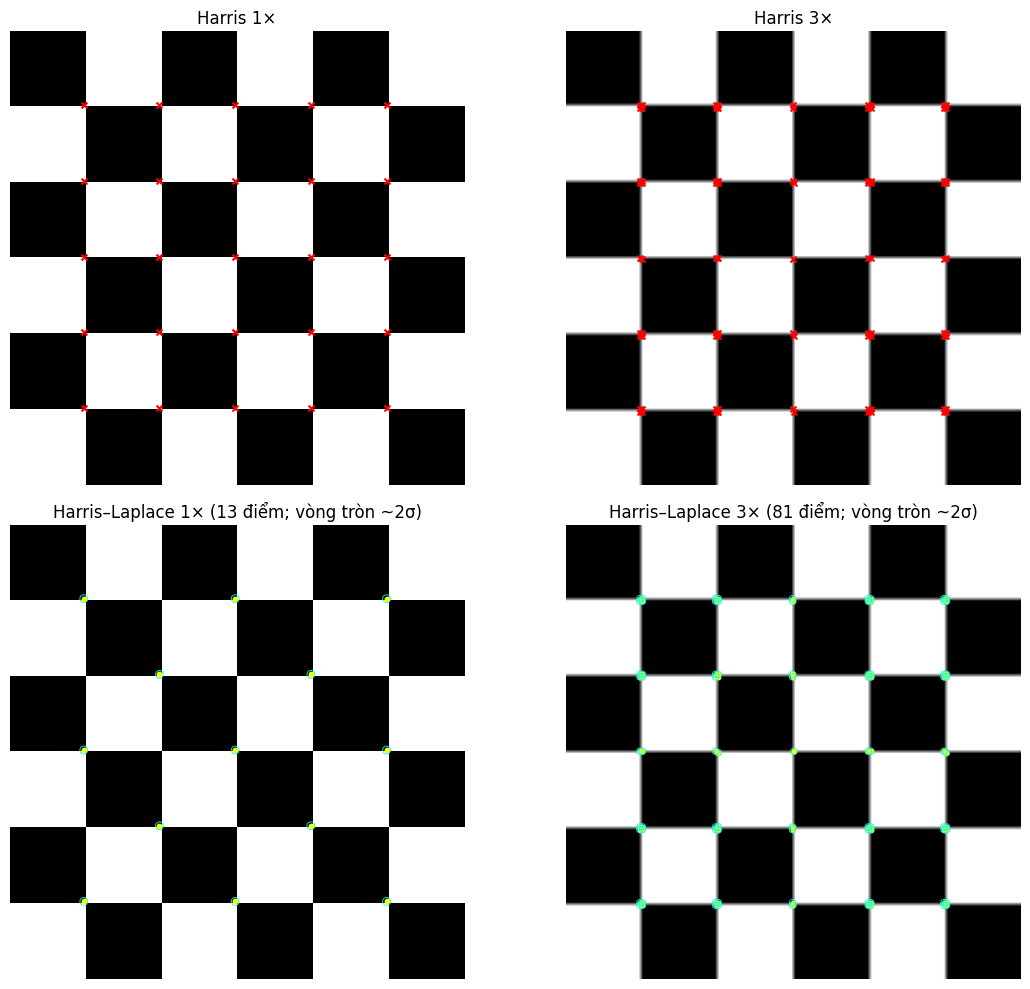

In [4]:
fig, ax = plt.subplots(2,2,figsize=(12,10))
plot_corners(img_small,p_h_small,ax=ax[0,0],title="Harris 1×")
plot_corners(img_large,p_h_large,ax=ax[0,1],title="Harris 3×")
for a, image, pts, name in [(ax[1,0],img_small,p_hl_small,"Harris–Laplace 1×"),
                            (ax[1,1],img_large,p_hl_large,"Harris–Laplace 3×")]:
    a.imshow(image,cmap="gray")
    if len(pts):
        a.scatter(pts[:,1],pts[:,0],s=10,c="yellow",marker="o")
        for r,c,sigma,_ in pts[:80]:
            a.add_patch(plt.Circle((c,r),radius=2*sigma,fill=False,color="cyan",lw=.6))
    a.set_title(name+f" ({len(pts)} điểm; vòng tròn ~2σ)"); a.axis("off")
plt.tight_layout(); plt.show()

### Đánh giá tỉ lệ được chọn

Đối với các điểm không gian khớp nhau sau phép phóng to, ta so sánh `sigma_large / (3*sigma_small)`. Giá trị gần 1 thể hiện scale được chọn biến đổi gần tương ứng với hệ số phóng to. Sai khác có thể do lấy mẫu pixel, bước rời rạc của tháp tỉ lệ, nội suy và cấu trúc bàn cờ có cạnh rất sắc.

In [5]:
if len(p_hl_small) and len(p_hl_large):
    mapped = np.column_stack((3*p_hl_small[:,0],3*p_hl_small[:,1]))
    distance_matrix = np.sqrt(np.sum((mapped[:, None, :] - p_hl_large[None, :, :2]) ** 2, axis=2))
    idx = np.argmin(distance_matrix, axis=1)
    dist = distance_matrix[np.arange(len(mapped)), idx]
    matched = dist <= 4.0
    ratios = p_hl_large[idx[matched],2] / (3*p_hl_small[matched,2])
    print("Số điểm không gian khớp:", int(matched.sum()), "/", len(p_hl_small))
    if len(ratios):
        print("Tỉ số sigma_large/(3*sigma_small): median=", round(float(np.median(ratios)),3),
              "mean=", round(float(np.mean(ratios)),3))
else:
    print("Không có điểm để so sánh scale; hãy tăng dải sigmas hoặc kiểm tra ảnh.")

Số điểm không gian khớp: 13 / 13
Tỉ số sigma_large/(3*sigma_small): median= 0.829 mean= 0.829


## 3. Quét hệ số `xi`

`xi` là tỉ số giữa hai mức scale kề nhau. `xi` quá lớn làm tháp thưa, có thể bỏ lỡ cực trị; `xi` gần 1 tạo tháp mịn nhưng cần nhiều tầng hơn để phủ cùng dải scale.

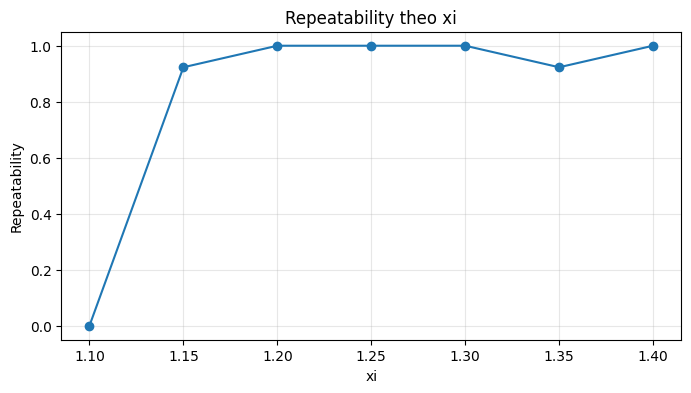

xi=1.10: repeatability=0.000, điểm ảnh nhỏ=25
xi=1.15: repeatability=0.923, điểm ảnh nhỏ=13
xi=1.20: repeatability=1.000, điểm ảnh nhỏ=13
xi=1.25: repeatability=1.000, điểm ảnh nhỏ=25
xi=1.30: repeatability=1.000, điểm ảnh nhỏ=13
xi=1.35: repeatability=0.923, điểm ảnh nhỏ=13
xi=1.40: repeatability=1.000, điểm ảnh nhỏ=13


In [6]:
xis = [1.10,1.15,1.20,1.25,1.30,1.35,1.40]
repeat_xi=[]; count_xi=[]
for xi in xis:
    sa=scale_pyramid(0.25,xi,10)
    sb=scale_pyramid(0.25,xi,16)
    a=harris_laplace(img_small,sa,log_thresh=0.0)
    b=harris_laplace(img_large,sb,log_thresh=0.0)
    repeat_xi.append(repeatability(a,b,transform_3x,img_large.shape,eps=4.0))
    count_xi.append(len(a))
plt.figure(figsize=(8,4)); plt.plot(xis,repeat_xi,marker="o")
plt.xlabel("xi"); plt.ylabel("Repeatability"); plt.title("Repeatability theo xi")
plt.grid(alpha=.3); plt.show()
for x,r,n in zip(xis,repeat_xi,count_xi): print(f"xi={x:.2f}: repeatability={r:.3f}, điểm ảnh nhỏ={n}")

## 4. Quét số tầng `n_levels`

Tăng `n_levels` mở rộng dải scale được khảo sát. Với ảnh phóng to 3×, ảnh lớn cần số tầng đủ để vươn tới các scale tương ứng.

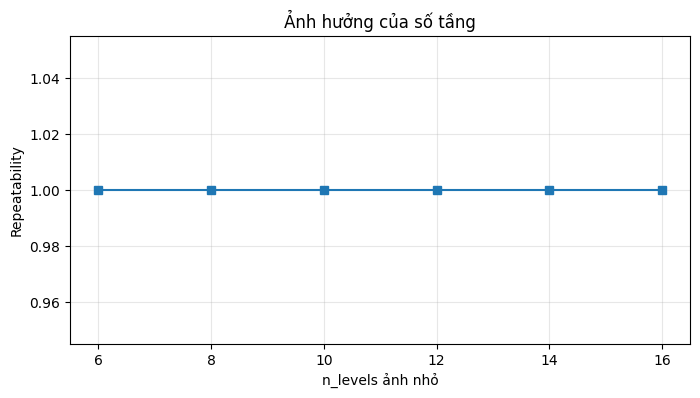

[(6, np.float64(0.622), np.float64(1.0)), (8, np.float64(0.896), np.float64(1.0)), (10, np.float64(1.29), np.float64(1.0)), (12, np.float64(1.858), np.float64(1.0)), (14, np.float64(2.675), np.float64(1.0)), (16, np.float64(3.852), np.float64(1.0))]


In [7]:
levels=[6,8,10,12,14,16]
rep_levels=[]; max_scales=[]
for n in levels:
    sa=scale_pyramid(0.25,1.2,n)
    sb=scale_pyramid(0.25,1.2,n+6)
    a=harris_laplace(img_small,sa,log_thresh=0.0)
    b=harris_laplace(img_large,sb,log_thresh=0.0)
    rep_levels.append(repeatability(a,b,transform_3x,img_large.shape,eps=4.0))
    max_scales.append(sa[-1])
plt.figure(figsize=(8,4)); plt.plot(levels,rep_levels,marker="s")
plt.xlabel("n_levels ảnh nhỏ"); plt.ylabel("Repeatability"); plt.title("Ảnh hưởng của số tầng")
plt.grid(alpha=.3); plt.show()
print(list(zip(levels,np.round(max_scales,3),np.round(rep_levels,3))))

## 5. Quét `log_thresh`

`log_thresh` loại ứng viên có LoG chuẩn hóa quá yếu. Ngưỡng tăng thường làm giảm số điểm; đổi lại có thể loại bỏ phản hồi không rõ cực trị scale. Không nên tự đặt kết luận về “ngưỡng tối ưu” trước khi xem số liệu.

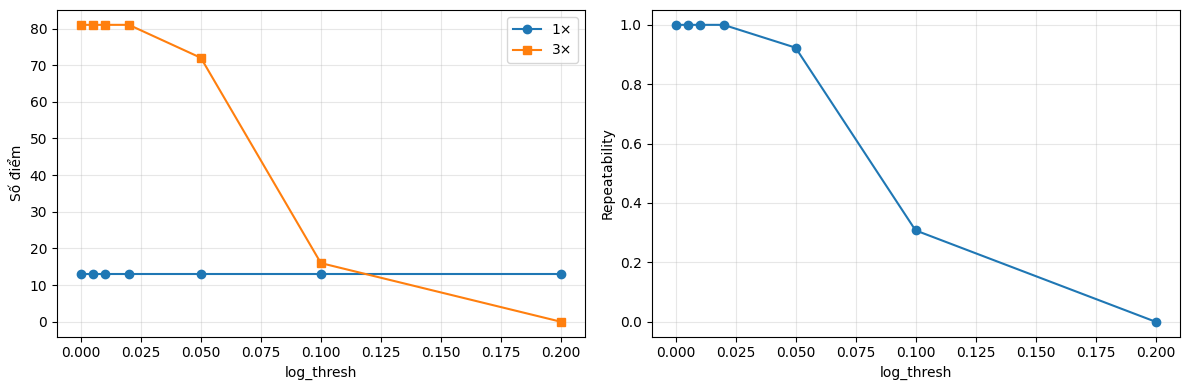

In [8]:
log_thresholds=[0.0,0.005,0.01,0.02,0.05,0.10,0.20]
counts_a=[]; counts_b=[]; reps=[]
for lt in log_thresholds:
    a=harris_laplace(img_small,sigmas_small,log_thresh=lt)
    b=harris_laplace(img_large,sigmas_large,log_thresh=lt)
    counts_a.append(len(a)); counts_b.append(len(b))
    reps.append(repeatability(a,b,transform_3x,img_large.shape,eps=4.0))
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(log_thresholds,counts_a,marker="o",label="1×")
ax[0].plot(log_thresholds,counts_b,marker="s",label="3×")
ax[0].set_xlabel("log_thresh"); ax[0].set_ylabel("Số điểm"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(log_thresholds,reps,marker="o"); ax[1].set_xlabel("log_thresh")
ax[1].set_ylabel("Repeatability"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 6. Kết luận

- Harris–Laplace gồm Harris đa tỉ lệ và bước chọn scale bằng cực đại địa phương của LoG chuẩn hóa.
- Scale `sigma` là thông tin thêm mà Harris cổ điển không cung cấp.
- `xi`, `n_levels`, `log_thresh` điều khiển mật độ tháp, dải kích thước và mức lọc ứng viên.
- Repeatability không nên được diễn giải một mình: cần xem cả số lượng điểm, tọa độ khớp và tỉ lệ scale được chọn. Với cấu trúc tổng hợp có cạnh sắc, Harris cổ điển đôi khi vẫn tìm lại đúng tọa độ dù không có scale selection.